In [1]:
# conda env 'era5'

import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import metpy.calc as mpcalc
from metpy.units import units
import cartopy.feature as cfeature
import numpy as np
from matplotlib.widgets import Slider, Button

In [2]:
center_lat = 19.845
center_lon = 120.4505

In [3]:
eraFile_surface = '../../data/era5/ERA5_surface_CAMP2Ex_RF17.nc'
era_data_surface = xr.open_dataset(eraFile_surface)
era_data_surface_sub = era_data_surface.isel(valid_time=1)

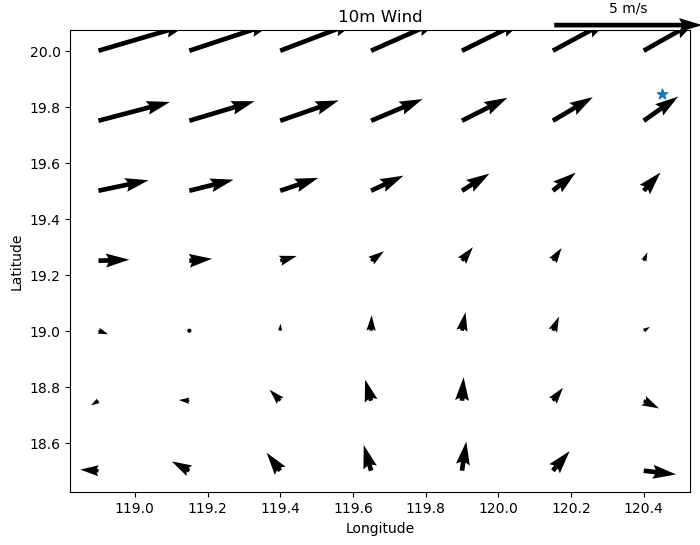

In [4]:
f, ax = plt.subplots(1, 1, figsize=(8, 6))
q0 = ax.quiver(era_data_surface_sub.longitude, era_data_surface_sub.latitude, era_data_surface_sub.u10, era_data_surface_sub.v10)
ax.quiverkey(q0, 0.9, 1.01, 5, label='5 m/s', labelpos='N')
ax.set_title('10m Wind')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.scatter(center_lon, center_lat, marker='*', s=60)

In [5]:
surface_center = era_data_surface.sel(latitude=center_lat, longitude=center_lon, method='nearest').isel(valid_time=1).copy(deep=True)
print('Surface Velocity East: {:.3f} m/s'.format(surface_center.u10.data))
print('Surface Velocity North: {:.3f} m/s'.format(surface_center.v10.data))
print('Surface Wind Speed: {:.3f} m/s'.format((surface_center.u10.data**2 + surface_center.v10.data**2)**0.5))

Surface Velocity East: 1.162 m/s
Surface Velocity North: 0.815 m/s
Surface Wind Speed: 1.419 m/s
